In [1]:
#Packages used in this project
import pandas as pd
import numpy as np

import seaborn as sns
sns.set_style("whitegrid")
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from lightgbm import LGBMClassifier, LGBMRegressor, early_stopping
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import roc_curve, roc_auc_score, mean_squared_error

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
data = pd.concat([train.drop(columns=['target', 'ID']), test.drop(columns=['ID'])], axis=0)

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4459 entries, 0 to 4458
Columns: 4993 entries, ID to 9fc776466
dtypes: float64(1845), int64(3147), object(1)
memory usage: 169.9+ MB


In [4]:
train.shape

(4459, 4993)

In [5]:
train.select_dtypes(include='object')

,ID
0,000d6aaf2
1,000fbd867
2,0027d6b71
3,0028cbf45
4,002a68644
...,...
4454,ff85154c8
4455,ffb6b3f4f
4456,ffcf61eb6
4457,ffea67e98


In [6]:
train_missing_values = train.isnull().sum()
train_missing_values = train_missing_values[train_missing_values > 0]
print(train_missing_values)

Series([], dtype: int64)


In [7]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49342 entries, 0 to 49341
Columns: 4992 entries, ID to 9fc776466
dtypes: float64(4991), object(1)
memory usage: 1.8+ GB


In [8]:
test.shape

(49342, 4992)

In [9]:
test.select_dtypes(include='object')

,ID
0,000137c73
1,00021489f
2,0004d7953
3,00056a333
4,00056d8eb
...,...
49337,fff73b677
49338,fff7b5923
49339,fff7c698f
49340,fff8dba89


In [10]:
test_missing_values = test.isnull().sum()
test_missing_values = test_missing_values[test_missing_values > 0]
print(test_missing_values)

Series([], dtype: int64)


In [11]:
train = train.drop("ID", axis=1)
IDs = test.pop("ID")

In [12]:
train_statistics = pd.DataFrame(zip(train.mean(), train.var()), columns=["Mean", "Variance"])

In [13]:
train_statistics

,Mean,Variance
0,5.944923e+06,6.780389e+13
1,1.465493e+04,1.515777e+11
2,1.390895e+03,4.132307e+09
3,2.672245e+04,3.248603e+11
4,4.530164e+03,5.565466e+10
...,...,...
4987,1.213809e+05,2.228509e+13
4988,3.573451e+04,2.607005e+12
4989,3.123741e+05,1.864945e+13
4990,9.219960e+04,2.676474e+12


[Text(0.5, 1.0, 'Means of the features')]

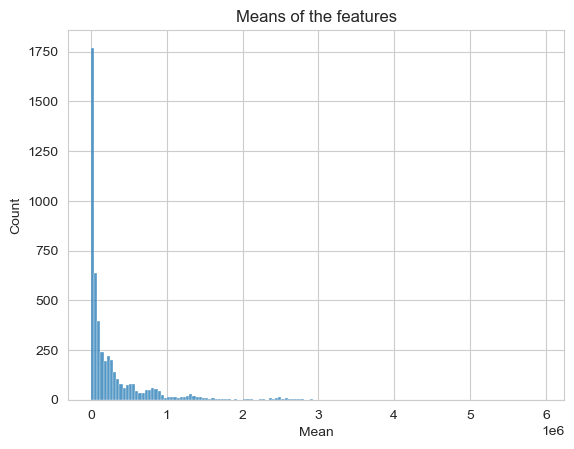

In [14]:
sns.histplot(data=train_statistics["Mean"], palette="hls").set(title="Means of the features")

[Text(0.5, 1.0, 'Variances of the features')]

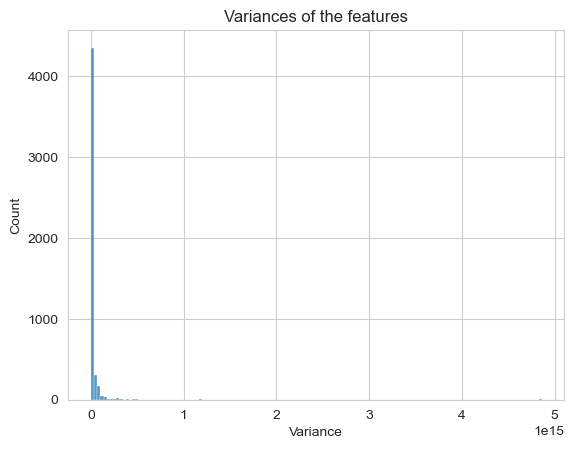

In [15]:
sns.histplot(data=train_statistics["Variance"], palette="hls").set(title="Variances of the features")

In [16]:
# a rigorous filtering strategy  for the train dataset which is essential
# features that are all zero everywhere
all_zero_features = [c for c in train.columns if (train[c] == 0).all()]
print("Features that are zero:", len(all_zero_features))

# features with constant values
constant_features = [c for c in train.columns if train[c].nunique() == 1]
print("Features with constant values:", len(constant_features))

# duplicates
dupes = train.drop(columns=constant_features).T.duplicated()
duplicate_features = dupes[dupes].index.tolist()
print("Features with duplicate values:", len(duplicate_features))

Features that are zero: 256
Features with constant values: 256
Features with duplicate values: 5


Performed the same operation on the test dataset and no such features were found. Additionally, checked for highly correlated features with correlation higher than a threshold (0.99) which also was not found.

In [17]:
features = [c for c in data.columns if c not in constant_features and c not in duplicate_features]

In [18]:
target_corr = train[features].astype('float32').apply(lambda col: col.corr(np.log1p(train["target"])))
target_corr = target_corr.sort_values(key=abs, ascending=False)
print(target_corr.head(30))

9fd594eec    0.197227
f190486d6    0.195313
6eef030c1    0.194630
58e2e02e6    0.187259
70feb1494    0.173549
f74e8f13d    0.172804
26fc93eb7    0.172285
1702b5bf0    0.168431
fb49e4212    0.167091
58232a6fb    0.163608
fc99f9426    0.161864
1c71183bb    0.160103
20aa07010    0.159419
324921c7b    0.159375
ba4ceabc5    0.158138
963a49cdc    0.157060
b43a7cfd5    0.157013
f3cf9341c    0.155248
491b9ee45    0.154638
e1d0e11b5    0.153776
0e1f6696a    0.153263
eeb9cd3aa    0.153056
555f18bd3    0.153014
c8d582dd2    0.152873
9d5c7cb94    0.152748
d6bb78916    0.152660
66ace2992    0.152624
15ace8c9f    0.152088
ac30af84a    0.149510
f14b57b8f    0.149012
dtype: float64


In [19]:
# Adversarial validation
n_train = len(train)
adv_X = data[features]
adv_y = np.concatenate([np.zeros(n_train), np.ones(len(data) - n_train)])
 
adv_model = LGBMClassifier(n_estimators=200, random_state=42)
adv_auc_cv = cross_val_score(adv_model, adv_X, adv_y, cv=5, scoring='roc_auc')
print(f"Adversarial AUC (5-fold): {adv_auc_cv.mean():.3f} +/- {adv_auc_cv.std():.3f}")
 
adv_model.fit(adv_X, adv_y)
adv_probailities = adv_model.predict_proba(adv_X)[:, 1]
false_positive_rate, true_positive_rate, _ = roc_curve(adv_y, adv_probailities)

[LightGBM] [Info] Number of positive: 39473, number of negative: 3567
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 1.992059 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 689196
[LightGBM] [Info] Number of data points in the train set: 43040, number of used features: 4730
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.917124 -> initscore=2.403892
[LightGBM] [Info] Start training from score 2.403892
[LightGBM] [Info] Number of positive: 39474, number of negative: 3567
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 2.067988 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 690371
[LightGBM] [Info] Number of data points in the train set: 43041, number of used features: 4730
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.917126 -> initscore=2.403917

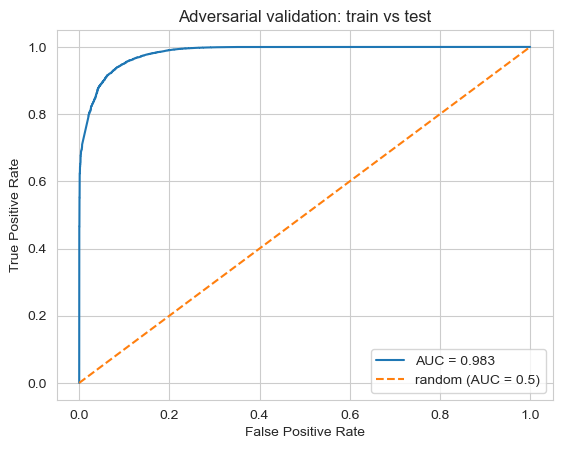

In [20]:
plt.plot(false_positive_rate, true_positive_rate, label=f'AUC = {roc_auc_score(adv_y, adv_probailities):.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='random (AUC = 0.5)')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Adversarial validation: train vs test")
plt.legend()
plt.show()

In [21]:
# if AUC is high, inspect which features are driving the shift:
shift_importance = pd.Series(adv_model.feature_importances_, index=features)
print(shift_importance.sort_values(ascending=False).head(20))

58e2e02e6    28
9fd594eec    23
0ff32eb98    23
f190486d6    21
91f701ba2    19
adb64ff71    19
15ace8c9f    18
20aa07010    17
c5a231d81    17
324921c7b    17
1702b5bf0    16
66ace2992    15
58e056e12    15
b625fe55a    15
6619d81fc    15
70feb1494    14
d6bb78916    14
190db8488    14
9df4daa99    14
26628e8d8    13
dtype: int32


In [22]:
# log transform
train_log = np.log1p(train[features])
test_log = np.log1p(test[features])

In [23]:
def rmsle_log_space(y_true_log, y_predicted_log):
    return np.sqrt(mean_squared_error(y_true_log, y_predicted_log))

In [25]:
# Baselines
y_log = np.log1p(train["target"])
kf = KFold(n_splits=5, shuffle=True, random_state=42)

LGB_PARAMS = dict(
    n_estimators=1000,
    learning_rate=0.01,
    num_leaves=15,
    min_child_samples=30,
    feature_fraction=0.7,
    bagging_fraction=0.7,
    bagging_freq=1,
    random_state=42
)

mean_scores, lgb_scores = [], []

for train_idx, val_idx in kf.split(train):
    y_true, y_validation = y_log.iloc[train_idx], y_log.iloc[val_idx]

    # regularized LightGBM baseline — kept conservative since features > rows
    X_true = train[features].iloc[train_idx]
    X_validation = train[features].iloc[val_idx]
    model = LGBMRegressor(**LGB_PARAMS)
    model.fit(
        X_true, y_true,
        eval_set=[(X_validation, y_validation)],
        callbacks=[early_stopping(50, verbose=False)],
    )
    lgb_predicted = model.predict(X_validation, num_iteration=model.best_iteration_)
    lgb_scores.append(rmsle_log_space(y_validation, lgb_predicted))

print(f"LightGBM baseline RMSLE: {np.mean(lgb_scores):.4f}")

[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.100532 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 128832
[LightGBM] [Info] Number of data points 

In [26]:
ranked_features = [f for f in target_corr.index.tolist() if f in features]
 
sweep_results = {}
for k in [100, 200, 300, 500, 1000]:
    top_k = ranked_features[:k]
    fold_scores = []
    for train_idx, val_idx in kf.split(train):
        y_true, y_validation = y_log.iloc[train_idx], y_log.iloc[val_idx]
        X_true = train[top_k].iloc[train_idx]
        X_validation = train[top_k].iloc[val_idx]
        model = LGBMRegressor(**LGB_PARAMS)
        model.fit(
            X_true, y_true,
            eval_set=[(X_validation, y_validation)],
            callbacks=[early_stopping(50, verbose=False)],
        )
        prediction = model.predict(X_validation, num_iteration=model.best_iteration_)
        fold_scores.append(rmsle_log_space(y_validation, prediction))
    sweep_results[k] = np.mean(fold_scores)
    print(f"top {k} features -> RMSLE {sweep_results[k]:.4f}")
 
best_k = min(sweep_results, key=sweep_results.get)
print(f"\nbest feature count: {best_k} (RMSLE {sweep_results[best_k]:.4f})")

[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009691 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 15179
[LightGBM] [Info] Number of data points i

In [27]:
best_features = ranked_features[:best_k]
 
final_model = LGBMRegressor(**LGB_PARAMS)
final_model.fit(train[best_features], y_log)
 
test_pred_log = final_model.predict(test[best_features])
test_pred = np.expm1(test_pred_log)

[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.027556 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 43507
[LightGBM] [Info] Number of data points in the train set: 4459, number of used features: 300
[LightGBM] [

In [28]:
feature_importance = pd.Series(final_model.feature_importances_, index=best_features)
print(feature_importance.sort_values(ascending=False).head(30))

f190486d6    356
58e2e02e6    314
eeb9cd3aa    290
15ace8c9f    268
b43a7cfd5    231
20aa07010    213
f74e8f13d    211
fb0f5dbfe    200
9fd594eec    194
1702b5bf0    193
d6bb78916    187
6eef030c1    182
58232a6fb    177
2288333b4    170
c47340d97    168
1184df5c2    164
024c577b9    164
491b9ee45    161
66ace2992    158
58e056e12    158
5c6487af1    148
62e59a501    140
190db8488    135
bb1113dbb    132
fb49e4212    131
fc99f9426    128
26fc93eb7    116
1db387535    114
324921c7b    113
0572565c2    113
dtype: int32


In [29]:
submission = pd.DataFrame({"ID": IDs, "target": test_pred})
submission.to_csv("submission.csv", index=False)

Break a leg, Shakil JOon
